In [24]:
# Import pandas for data manipulation
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# TF-IDF converts text/categorical information such as genres
# into numerical vectors
from sklearn.feature_extraction.text import TfidfVectorizer

# OneHotEncoder converts categorical values such as TV, Movie, OVA
# into numerical binary columns
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Used to combine multiple feature matrices
from scipy.sparse import hstack

# Data preprocessing

In [3]:
# Load the dataset
df = pd.read_csv("anime.csv")

# Display the first 5 rows
df.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


In [4]:
# Display the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 12294
Number of columns: 7


In [5]:
# Display information about the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 672.5+ KB


In [6]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64


In [7]:
# Calculate the percentage of missing values in each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display missing value percentage
print("Missing value percentage:")
print(missing_percentage)

Missing value percentage:
anime_id    0.000000
name        0.000000
genre       0.504311
type        0.203351
episodes    0.000000
rating      1.870831
members     0.000000
dtype: float64


In [8]:
# Create a summary table for missing values
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

print(missing_summary)

          Missing Values  Percentage
anime_id               0    0.000000
name                   0    0.000000
genre                 62    0.504311
type                  25    0.203351
episodes               0    0.000000
rating               230    1.870831
members                0    0.000000


In [9]:
# Count the number of duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
# Check whether anime_id contains duplicates
duplicate_ids = df["anime_id"].duplicated().sum()

print("Duplicate anime IDs:", duplicate_ids)

Duplicate anime IDs: 0


In [12]:
# Replace missing genre values with "Unknown"
df["genre"] = df["genre"].fillna("Unknown")
# Replace missing type values with "Unknown"
df["type"] = df["type"].fillna("Unknown")

In [13]:
# Replace missing ratings with the median rating
df["rating"] = df["rating"].fillna(df["rating"].median())

In [14]:
# Check missing values after preprocessing
print(df.isnull().sum())

anime_id    0
name        0
genre       0
type        0
episodes    0
rating      0
members     0
dtype: int64


In [15]:
# Display unique values from the episodes column
print(df["episodes"].unique()[:20])

['1' '64' '51' '24' '10' '148' '110' '13' '201' '25' '22' '75' '4' '26'
 '12' '27' '43' '74' '37' '2']


In [16]:
# Replace "Unknown" with NaN
df["episodes"] = df["episodes"].replace("Unknown", np.nan)

# Convert episodes from object to numeric
df["episodes"] = pd.to_numeric(df["episodes"], errors="coerce")

# Fill missing episode values with the median
df["episodes"] = df["episodes"].fillna(df["episodes"].median())

In [17]:
# Display the data types after preprocessing
print(df.dtypes)

anime_id      int64
name         object
genre        object
type         object
episodes    float64
rating      float64
members       int64
dtype: object


In [18]:
# Display statistical summary of numerical columns
df.describe()

,anime_id,episodes,rating,members
count,12294.000000,12294.000000,12294.000000,1.229400e+04
mean,14058.221653,12.095412,6.475700,1.807134e+04
std,11455.294701,46.244062,1.017179,5.482068e+04
min,1.000000,1.000000,1.670000,5.000000e+00
25%,3484.250000,1.000000,5.900000,2.250000e+02
50%,10260.500000,2.000000,6.570000,1.550000e+03
75%,24794.500000,12.000000,7.170000,9.437000e+03
max,34527.000000,1818.000000,10.000000,1.013917e+06


In [20]:
# Count anime by broadcast type
print(df["type"].value_counts())
# Display the most common genre combinations
print(df["genre"].value_counts().head(10))

type
TV         3787
OVA        3311
Movie      2348
Special    1676
ONA         659
Music       488
Unknown      25
Name: count, dtype: int64
genre
Hentai                   823
Comedy                   523
Music                    301
Kids                     199
Comedy, Slice of Life    179
Dementia                 137
Fantasy, Kids            128
Fantasy                  114
Comedy, Kids             112
Drama                    107
Name: count, dtype: int64


In [21]:
# Display basic information about ratings
print("Minimum rating:", df["rating"].min())
print("Maximum rating:", df["rating"].max())
print("Average rating:", df["rating"].mean())
print("Median rating:", df["rating"].median())

Minimum rating: 1.67
Maximum rating: 10.0
Average rating: 6.47569952822515
Median rating: 6.57


In [22]:
# Display the first 10 rows after preprocessing
df.head(10)

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266
5,32935,Haikyuu!!: Karasuno Koukou VS Shiratorizawa Ga...,"Comedy, Drama, School, Shounen, Sports",TV,10.0,9.15,93351
6,11061,Hunter x Hunter (2011),"Action, Adventure, Shounen, Super Power",TV,148.0,9.13,425855
7,820,Ginga Eiyuu Densetsu,"Drama, Military, Sci-Fi, Space",OVA,110.0,9.11,80679
8,15335,Gintama Movie: Kanketsu-hen - Yorozuya yo Eien...,"Action, Comedy, Historical, Parody, Samurai, S...",Movie,1.0,9.10,72534
9,15417,Gintama&#039;: Enchousen,"Action, Comedy, Historical, Parody, Samurai, S...",TV,13.0,9.11,81109


In [23]:
# Display final dataset dimensions
print("Final dataset shape:", df.shape)

Final dataset shape: (12294, 7)


# Feature Engineering

In [25]:
# Display the columns available in the cleaned dataset
print("Available columns:")
print(df.columns.tolist())

Available columns:
['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members']


In [26]:
# Features that will be used for calculating similarity
selected_features = [
    "genre",
    "type",
    "episodes",
    "rating",
    "members"
]

print("Selected features:")
print(selected_features)

Selected features:
['genre', 'type', 'episodes', 'rating', 'members']


In [27]:
# Display some genre values
print(df["genre"].head(10))

0                 Drama, Romance, School, Supernatural
1    Action, Adventure, Drama, Fantasy, Magic, Mili...
2    Action, Comedy, Historical, Parody, Samurai, S...
3                                     Sci-Fi, Thriller
4    Action, Comedy, Historical, Parody, Samurai, S...
5               Comedy, Drama, School, Shounen, Sports
6              Action, Adventure, Shounen, Super Power
7                       Drama, Military, Sci-Fi, Space
8    Action, Comedy, Historical, Parody, Samurai, S...
9    Action, Comedy, Historical, Parody, Samurai, S...
Name: genre, dtype: object


In [28]:
# Create a TF-IDF vectorizer
tfidf = TfidfVectorizer(
    token_pattern=r'[^,]+',
    lowercase=True
)

# Convert the genre column into TF-IDF numerical vectors
genre_matrix = tfidf.fit_transform(df["genre"])

# Display the shape of the resulting matrix
print("Genre feature matrix shape:", genre_matrix.shape)

Genre feature matrix shape: (12294, 83)


In [29]:
# Display the genre names recognized by TF-IDF
genre_features = tfidf.get_feature_names_out()

print("Genre features:")
print(genre_features)

Genre features:
[' adventure' ' cars' ' comedy' ' dementia' ' demons' ' drama' ' ecchi'
 ' fantasy' ' game' ' harem' ' hentai' ' historical' ' horror' ' josei'
 ' kids' ' magic' ' martial arts' ' mecha' ' military' ' music' ' mystery'
 ' parody' ' police' ' psychological' ' romance' ' samurai' ' school'
 ' sci-fi' ' seinen' ' shoujo' ' shoujo ai' ' shounen' ' shounen ai'
 ' slice of life' ' space' ' sports' ' super power' ' supernatural'
 ' thriller' ' vampire' ' yaoi' ' yuri' 'action' 'adventure' 'cars'
 'comedy' 'dementia' 'demons' 'drama' 'ecchi' 'fantasy' 'game' 'harem'
 'hentai' 'historical' 'horror' 'josei' 'kids' 'magic' 'martial arts'
 'mecha' 'military' 'music' 'mystery' 'parody' 'police' 'psychological'
 'romance' 'samurai' 'school' 'sci-fi' 'seinen' 'shoujo' 'shounen'
 'slice of life' 'space' 'sports' 'super power' 'supernatural' 'thriller'
 'unknown' 'vampire' 'yaoi']


In [30]:
# Convert a small portion of the TF-IDF matrix into a DataFrame
genre_sample = pd.DataFrame(
    genre_matrix[:5].toarray(),
    columns=genre_features
)

display(genre_sample)

,adventure,cars,comedy,dementia,demons,drama,ecchi,fantasy,game,harem,...,shounen,slice of life,space,sports,super power,supernatural,thriller,unknown,vampire,yaoi
0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.397652,0.0,0.000000,0.0,0.0,0.382293,0.0,0.319633,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000000,0.0,0.317195,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.0,0.317195,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
# Create a OneHotEncoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

# Convert the type column into numerical representation
type_matrix = encoder.fit_transform(df[["type"]])

# Display the shape
print("Type feature matrix shape:", type_matrix.shape)

Type feature matrix shape: (12294, 7)


In [32]:
# Get the names of the encoded type features
type_features = encoder.get_feature_names_out(["type"])

print("Encoded type features:")
print(type_features)

Encoded type features:
['type_Movie' 'type_Music' 'type_ONA' 'type_OVA' 'type_Special' 'type_TV'
 'type_Unknown']


In [33]:
# Select numerical features
numerical_features = df[
    ["episodes", "rating", "members"]
]

# Display the first five rows
display(numerical_features.head())

,episodes,rating,members
0,1.0,9.37,200630
1,64.0,9.26,793665
2,51.0,9.25,114262
3,24.0,9.17,673572
4,51.0,9.16,151266


In [34]:
# Display descriptive statistics for numerical features
print("Numerical feature statistics:")
display(numerical_features.describe())

Numerical feature statistics:


,episodes,rating,members
count,12294.000000,12294.000000,1.229400e+04
mean,12.095412,6.475700,1.807134e+04
std,46.244062,1.017179,5.482068e+04
min,1.000000,1.670000,5.000000e+00
25%,1.000000,5.900000,2.250000e+02
50%,2.000000,6.570000,1.550000e+03
75%,12.000000,7.170000,9.437000e+03
max,1818.000000,10.000000,1.013917e+06


In [35]:
# Create a StandardScaler
scaler = StandardScaler()

# Standardize numerical features
numerical_matrix = scaler.fit_transform(numerical_features)

# Display the first five standardized rows
print("Normalized numerical features:")
display(pd.DataFrame(
    numerical_matrix,
    columns=["episodes", "rating", "members"]
).head())

Normalized numerical features:


,episodes,rating,members
0,-0.239941,2.845534,3.330241
1,1.122451,2.737388,14.148406
2,0.841323,2.727556,1.754713
3,0.257440,2.648904,11.957666
4,0.841323,2.639073,2.429742


In [36]:
# Convert the standardized numerical matrix into a sparse matrix
from scipy.sparse import csr_matrix

numerical_sparse = csr_matrix(numerical_matrix)

print("Numerical sparse matrix shape:", numerical_sparse.shape)

Numerical sparse matrix shape: (12294, 3)


In [37]:
# Combine all feature matrices horizontally
feature_matrix = hstack([
    genre_matrix,
    type_matrix,
    numerical_sparse
])

print("Final feature matrix shape:", feature_matrix.shape)

Final feature matrix shape: (12294, 93)


In [38]:
# Display information about the final feature matrix
print("Number of anime:", feature_matrix.shape[0])
print("Number of features:", feature_matrix.shape[1])

Number of anime: 12294
Number of features: 93


In [39]:
# Create names for numerical features
numerical_feature_names = [
    "episodes_scaled",
    "rating_scaled",
    "members_scaled"
]

# Combine all feature names
all_feature_names = list(genre_features) + \
                    list(type_features) + \
                    numerical_feature_names

print("Total feature names:", len(all_feature_names))

print("\nFirst 20 features:")
print(all_feature_names[:20])

Total feature names: 93

First 20 features:
[' adventure', ' cars', ' comedy', ' dementia', ' demons', ' drama', ' ecchi', ' fantasy', ' game', ' harem', ' hentai', ' historical', ' horror', ' josei', ' kids', ' magic', ' martial arts', ' mecha', ' military', ' music']


In [40]:
# Convert only the first 5 rows into a DataFrame for inspection
sample_features = pd.DataFrame(
    feature_matrix[:5].toarray(),
    columns=all_feature_names
)

display(sample_features)

,adventure,cars,comedy,dementia,demons,drama,ecchi,fantasy,game,harem,...,type_Movie,type_Music,type_ONA,type_OVA,type_Special,type_TV,type_Unknown,episodes_scaled,rating_scaled,members_scaled
0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.239941,2.845534,3.330241
1,0.397652,0.0,0.000000,0.0,0.0,0.382293,0.0,0.319633,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.122451,2.737388,14.148406
2,0.000000,0.0,0.317195,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.841323,2.727556,1.754713
3,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.257440,2.648904,11.957666
4,0.000000,0.0,0.317195,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.841323,2.639073,2.429742


In [41]:
pd.DataFrame(feature_matrix.toarray())

,0,1,2,3,4,5,6,7,8,9,...,83,84,85,86,87,88,89,90,91,92
0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.239941,2.845534,3.330241
1,0.397652,0.0,0.000000,0.0,0.0,0.382293,0.0,0.319633,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.122451,2.737388,14.148406
2,0.000000,0.0,0.317195,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.841323,2.727556,1.754713
3,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.257440,2.648904,11.957666
4,0.000000,0.0,0.317195,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.841323,2.639073,2.429742
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12289,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-0.239941,-2.286514,-0.325809
12290,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-0.239941,-2.158704,-0.326320
12291,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-0.175066,-1.568814,-0.325663
12292,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-0.239941,-1.470498,-0.326466


# Recommendation System 

In [42]:
# Import cosine similarity function
from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity between all anime
cosine_sim = cosine_similarity(feature_matrix)

# Display the shape of the similarity matrix
print("Cosine Similarity Matrix Shape:", cosine_sim.shape)

Cosine Similarity Matrix Shape: (12294, 12294)


In [43]:
# Check the similarity of the first anime with itself
print("Self Similarity:", cosine_sim[0][0])

Self Similarity: 0.9999999999999998


In [44]:
# Compare the first anime with the second anime
print("Similarity between first and second anime:",
      cosine_sim[0][1])

Similarity between first and second anime: 0.816191583645134


In [45]:
# Create a mapping from anime name to DataFrame index
anime_indices = pd.Series(
    df.index,
    index=df["name"]
).drop_duplicates()

# Display the first 10 mappings
print(anime_indices.head(10))

name
Kimi no Na wa.                                               0
Fullmetal Alchemist: Brotherhood                             1
Gintama°                                                     2
Steins;Gate                                                  3
Gintama&#039;                                                4
Haikyuu!!: Karasuno Koukou VS Shiratorizawa Gakuen Koukou    5
Hunter x Hunter (2011)                                       6
Ginga Eiyuu Densetsu                                         7
Gintama Movie: Kanketsu-hen - Yorozuya yo Eien Nare          8
Gintama&#039;: Enchousen                                     9
dtype: int64


In [46]:
def recommend_anime(anime_name, top_n=10, threshold=0.0):
    """
    Recommend anime similar to the given anime.

    Parameters:
        anime_name : str
            Name of the target anime.

        top_n : int
            Maximum number of recommendations.

        threshold : float
            Minimum cosine similarity required.

    Returns:
        DataFrame containing recommended anime and similarity scores.
    """

    # Check whether the anime exists in the dataset
    if anime_name not in anime_indices:
        print(f"'{anime_name}' was not found in the dataset.")
        return pd.DataFrame()

    # Get the index of the target anime
    idx = anime_indices[anime_name]

    # If duplicate names exist, take the first matching index
    if isinstance(idx, pd.Series):
        idx = idx.iloc[0]

    # Get similarity scores for the selected anime
    similarity_scores = list(enumerate(cosine_sim[idx]))

    # Sort anime based on similarity score
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Remove the target anime itself
    similarity_scores = [
        (i, score)
        for i, score in similarity_scores
        if i != idx
    ]

    # Apply similarity threshold
    similarity_scores = [
        (i, score)
        for i, score in similarity_scores
        if score >= threshold
    ]

    # Select top N recommendations
    similarity_scores = similarity_scores[:top_n]

    # Extract anime indices
    anime_ids = [i for i, score in similarity_scores]

    # Extract similarity scores
    scores = [score for i, score in similarity_scores]

    # Create recommendation DataFrame
    recommendations = df.loc[anime_ids, [
        "anime_id",
        "name",
        "genre",
        "type",
        "episodes",
        "rating",
        "members"
    ]].copy()

    # Add similarity score
    recommendations["similarity_score"] = scores

    # Reset index
    recommendations = recommendations.reset_index(drop=True)

    return recommendations

In [47]:
# Display some anime names
print(df["name"].head(20).tolist())

['Kimi no Na wa.', 'Fullmetal Alchemist: Brotherhood', 'Gintama°', 'Steins;Gate', 'Gintama&#039;', 'Haikyuu!!: Karasuno Koukou VS Shiratorizawa Gakuen Koukou', 'Hunter x Hunter (2011)', 'Ginga Eiyuu Densetsu', 'Gintama Movie: Kanketsu-hen - Yorozuya yo Eien Nare', 'Gintama&#039;: Enchousen', 'Clannad: After Story', 'Koe no Katachi', 'Gintama', 'Code Geass: Hangyaku no Lelouch R2', 'Haikyuu!! Second Season', 'Sen to Chihiro no Kamikakushi', 'Shigatsu wa Kimi no Uso', 'Mushishi Zoku Shou 2nd Season', 'Ookami Kodomo no Ame to Yuki', 'Code Geass: Hangyaku no Lelouch']


In [48]:
recommendations = recommend_anime(
    "Cowboy Bebop",
    top_n=10
)

display(recommendations)

,anime_id,name,genre,type,episodes,rating,members,similarity_score
0,2001,Tengen Toppa Gurren Lagann,"Action, Adventure, Comedy, Mecha, Sci-Fi",TV,27.0,8.78,562962,0.994978
1,2904,Code Geass: Hangyaku no Lelouch R2,"Action, Drama, Mecha, Military, Sci-Fi, Super ...",TV,25.0,8.98,572888,0.992594
2,21,One Piece,"Action, Adventure, Comedy, Drama, Fantasy, Sho...",TV,2.0,8.58,504862,0.992520
3,30276,One Punch Man,"Action, Comedy, Parody, Sci-Fi, Seinen, Super ...",TV,12.0,8.82,552458,0.991092
4,22535,Kiseijuu: Sei no Kakuritsu,"Action, Drama, Horror, Psychological, Sci-Fi, ...",TV,24.0,8.59,425457,0.990170
5,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665,0.990165
6,30,Neon Genesis Evangelion,"Action, Dementia, Drama, Mecha, Psychological,...",TV,26.0,8.32,461946,0.989735
7,13601,Psycho-Pass,"Action, Police, Psychological, Sci-Fi",TV,22.0,8.50,509109,0.989447
8,205,Samurai Champloo,"Action, Adventure, Comedy, Historical, Samurai...",TV,26.0,8.50,390076,0.989444
9,121,Fullmetal Alchemist,"Action, Adventure, Comedy, Drama, Fantasy, Mag...",TV,51.0,8.33,600384,0.989442


In [49]:
# Select the first anime from the dataset
target_anime = df["name"].iloc[0]

print("Target Anime:", target_anime)

# Generate recommendations
recommendations = recommend_anime(
    target_anime,
    top_n=10
)

display(recommendations)

Target Anime: Kimi no Na wa.


,anime_id,name,genre,type,episodes,rating,members,similarity_score
0,10408,Hotarubi no Mori e,"Drama, Romance, Shoujo, Supernatural",Movie,1.0,8.61,197439,0.976168
1,7311,Suzumiya Haruhi no Shoushitsu,"Comedy, Mystery, Romance, School, Sci-Fi, Supe...",Movie,1.0,8.81,240297,0.965757
2,578,Hotaru no Haka,"Drama, Historical",Movie,1.0,8.58,174878,0.957389
3,16782,Kotonoha no Niwa,"Drama, Psychological, Romance, Slice of Life",Movie,1.0,8.35,189741,0.953035
4,513,Tenkuu no Shiro Laputa,"Adventure, Fantasy, Romance, Sci-Fi",Movie,1.0,8.38,151061,0.943432
5,12355,Ookami Kodomo no Ame to Yuki,"Fantasy, Slice of Life",Movie,1.0,8.84,226193,0.942378
6,11577,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,"Sci-Fi, Thriller",Movie,1.0,8.61,192424,0.938947
7,3784,Evangelion: 2.0 You Can (Not) Advance,"Action, Mecha, Sci-Fi",Movie,1.0,8.53,182224,0.936578
8,512,Majo no Takkyuubin,"Adventure, Comedy, Drama, Fantasy, Magic, Romance",Movie,1.0,8.27,152331,0.936148
9,11981,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku n...,"Drama, Magic, Psychological, Thriller",Movie,1.0,8.50,135735,0.935989


In [50]:
# Display only anime names and similarity scores
display(
    recommendations[
        ["name", "similarity_score"]
    ]
)

,name,similarity_score
0,Hotarubi no Mori e,0.976168
1,Suzumiya Haruhi no Shoushitsu,0.965757
2,Hotaru no Haka,0.957389
3,Kotonoha no Niwa,0.953035
4,Tenkuu no Shiro Laputa,0.943432
5,Ookami Kodomo no Ame to Yuki,0.942378
6,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,0.938947
7,Evangelion: 2.0 You Can (Not) Advance,0.936578
8,Majo no Takkyuubin,0.936148
9,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku n...,0.935989


In [51]:
# Select target anime
target_anime = df["name"].iloc[0]

# Different similarity thresholds
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

# Store results
threshold_results = []

for threshold in thresholds:

    # Generate recommendations using the threshold
    recommendations = recommend_anime(
        target_anime,
        top_n=100,
        threshold=threshold
    )

    # Count recommendations
    recommendation_count = len(recommendations)

    # Store the result
    threshold_results.append({
        "Threshold": threshold,
        "Number of Recommendations": recommendation_count
    })

# Convert results into DataFrame
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Number of Recommendations
0,0.3,100
1,0.4,100
2,0.5,100
3,0.6,100
4,0.7,100
5,0.8,100


In [52]:
# Test several thresholds
test_thresholds = [0.30, 0.50, 0.70]

for threshold in test_thresholds:

    print("\n" + "=" * 60)
    print("Threshold:", threshold)
    print("=" * 60)

    recommendations = recommend_anime(
        target_anime,
        top_n=10,
        threshold=threshold
    )

    if len(recommendations) > 0:
        display(
            recommendations[
                ["name", "similarity_score"]
            ]
        )
    else:
        print("No recommendations found.")


Threshold: 0.3


,name,similarity_score
0,Hotarubi no Mori e,0.976168
1,Suzumiya Haruhi no Shoushitsu,0.965757
2,Hotaru no Haka,0.957389
3,Kotonoha no Niwa,0.953035
4,Tenkuu no Shiro Laputa,0.943432
5,Ookami Kodomo no Ame to Yuki,0.942378
6,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,0.938947
7,Evangelion: 2.0 You Can (Not) Advance,0.936578
8,Majo no Takkyuubin,0.936148
9,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku n...,0.935989



Threshold: 0.5


,name,similarity_score
0,Hotarubi no Mori e,0.976168
1,Suzumiya Haruhi no Shoushitsu,0.965757
2,Hotaru no Haka,0.957389
3,Kotonoha no Niwa,0.953035
4,Tenkuu no Shiro Laputa,0.943432
5,Ookami Kodomo no Ame to Yuki,0.942378
6,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,0.938947
7,Evangelion: 2.0 You Can (Not) Advance,0.936578
8,Majo no Takkyuubin,0.936148
9,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku n...,0.935989



Threshold: 0.7


,name,similarity_score
0,Hotarubi no Mori e,0.976168
1,Suzumiya Haruhi no Shoushitsu,0.965757
2,Hotaru no Haka,0.957389
3,Kotonoha no Niwa,0.953035
4,Tenkuu no Shiro Laputa,0.943432
5,Ookami Kodomo no Ame to Yuki,0.942378
6,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,0.938947
7,Evangelion: 2.0 You Can (Not) Advance,0.936578
8,Majo no Takkyuubin,0.936148
9,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku n...,0.935989


In [53]:
# Test different thresholds
threshold_analysis = []

for threshold in thresholds:

    recommendations = recommend_anime(
        target_anime,
        top_n=100,
        threshold=threshold
    )

    if len(recommendations) > 0:

        average_similarity = (
            recommendations["similarity_score"].mean()
        )

        maximum_similarity = (
            recommendations["similarity_score"].max()
        )

        minimum_similarity = (
            recommendations["similarity_score"].min()
        )

    else:

        average_similarity = 0
        maximum_similarity = 0
        minimum_similarity = 0

    threshold_analysis.append({
        "Threshold": threshold,
        "Recommendation_Count": len(recommendations),
        "Average_Similarity": average_similarity,
        "Maximum_Similarity": maximum_similarity,
        "Minimum_Similarity": minimum_similarity
    })

threshold_analysis_df = pd.DataFrame(
    threshold_analysis
)

display(threshold_analysis_df)

,Threshold,Recommendation_Count,Average_Similarity,Maximum_Similarity,Minimum_Similarity
0,0.3,100,0.901208,0.976168,0.877305
1,0.4,100,0.901208,0.976168,0.877305
2,0.5,100,0.901208,0.976168,0.877305
3,0.6,100,0.901208,0.976168,0.877305
4,0.7,100,0.901208,0.976168,0.877305
5,0.8,100,0.901208,0.976168,0.877305


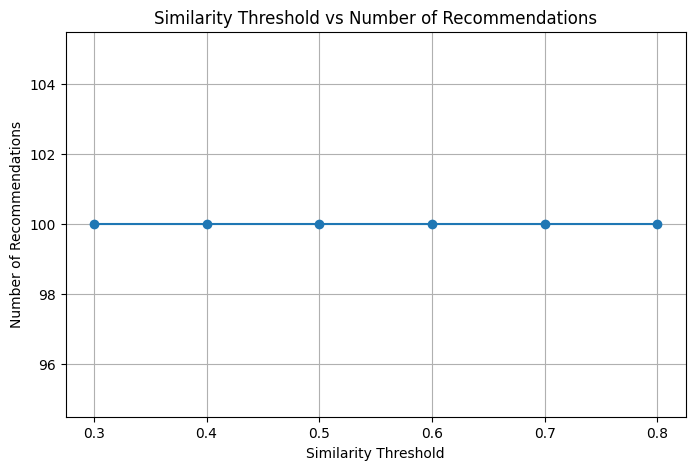

In [54]:
#Plot Threshold vs Number of Recommendations

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_analysis_df["Threshold"],
    threshold_analysis_df["Recommendation_Count"],
    marker="o"
)

plt.xlabel("Similarity Threshold")
plt.ylabel("Number of Recommendations")
plt.title("Similarity Threshold vs Number of Recommendations")

plt.grid(True)
plt.show()

In [55]:
# Generate recommendations
recommendations = recommend_anime(
    target_anime,
    top_n=20,
    threshold=0.50
)

# Check the distribution of anime types
print("Recommended Anime Types:")
print(recommendations["type"].value_counts())

Recommended Anime Types:
type
Movie    20
Name: count, dtype: int64


In [56]:
print("\nRecommended Anime Genres:")
print(recommendations["genre"].head(20))


Recommended Anime Genres:
0                  Drama, Romance, Shoujo, Supernatural
1     Comedy, Mystery, Romance, School, Sci-Fi, Supe...
2                                     Drama, Historical
3          Drama, Psychological, Romance, Slice of Life
4                   Adventure, Fantasy, Romance, Sci-Fi
5                                Fantasy, Slice of Life
6                                      Sci-Fi, Thriller
7                                 Action, Mecha, Sci-Fi
8     Adventure, Comedy, Drama, Fantasy, Magic, Romance
9                 Drama, Magic, Psychological, Thriller
10        Dementia, Drama, Mecha, Psychological, Sci-Fi
11                      Adventure, Comedy, Supernatural
12                                   Adventure, Fantasy
13    Action, Adventure, Horror, Military, Sci-Fi, S...
14    Action, Drama, Mystery, Romance, Supernatural,...
15                               Drama, School, Shounen
16    Action, Mecha, Police, Psychological, Sci-Fi, ...
17                Act

In [58]:
cosine_similarity(feature_matrix)
cosine_sim = cosine_similarity(feature_matrix)

In [59]:
def recommend_anime_memory_efficient(
    anime_name,
    top_n=10,
    threshold=0.0
):
    
    # Check whether anime exists
    if anime_name not in anime_indices:
        print(f"'{anime_name}' was not found.")
        return pd.DataFrame()

    # Get anime index
    idx = anime_indices[anime_name]

    if isinstance(idx, pd.Series):
        idx = idx.iloc[0]

    # Calculate similarity only for the selected anime
    similarity_scores = cosine_similarity(
        feature_matrix[idx],
        feature_matrix
    ).flatten()

    # Create index-score pairs
    scores = list(enumerate(similarity_scores))

    # Remove target anime
    scores = [
        (i, score)
        for i, score in scores
        if i != idx
    ]

    # Apply threshold
    scores = [
        (i, score)
        for i, score in scores
        if score >= threshold
    ]

    # Sort by similarity
    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Select top recommendations
    scores = scores[:top_n]

    # Extract indices
    indices = [i for i, score in scores]

    # Extract similarity values
    similarity_values = [
        score for i, score in scores
    ]

    # Create result
    result = df.loc[
        indices,
        [
            "anime_id",
            "name",
            "genre",
            "type",
            "episodes",
            "rating",
            "members"
        ]
    ].copy()

    result["similarity_score"] = similarity_values

    return result.reset_index(drop=True)

In [60]:
recommendations = recommend_anime_memory_efficient(
    target_anime,
    top_n=10,
    threshold=0.50
)

display(recommendations)

,anime_id,name,genre,type,episodes,rating,members,similarity_score
0,10408,Hotarubi no Mori e,"Drama, Romance, Shoujo, Supernatural",Movie,1.0,8.61,197439,0.976168
1,7311,Suzumiya Haruhi no Shoushitsu,"Comedy, Mystery, Romance, School, Sci-Fi, Supe...",Movie,1.0,8.81,240297,0.965757
2,578,Hotaru no Haka,"Drama, Historical",Movie,1.0,8.58,174878,0.957389
3,16782,Kotonoha no Niwa,"Drama, Psychological, Romance, Slice of Life",Movie,1.0,8.35,189741,0.953035
4,513,Tenkuu no Shiro Laputa,"Adventure, Fantasy, Romance, Sci-Fi",Movie,1.0,8.38,151061,0.943432
5,12355,Ookami Kodomo no Ame to Yuki,"Fantasy, Slice of Life",Movie,1.0,8.84,226193,0.942378
6,11577,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,"Sci-Fi, Thriller",Movie,1.0,8.61,192424,0.938947
7,3784,Evangelion: 2.0 You Can (Not) Advance,"Action, Mecha, Sci-Fi",Movie,1.0,8.53,182224,0.936578
8,512,Majo no Takkyuubin,"Adventure, Comedy, Drama, Fantasy, Magic, Romance",Movie,1.0,8.27,152331,0.936148
9,11981,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku n...,"Drama, Magic, Psychological, Thriller",Movie,1.0,8.50,135735,0.935989


In [61]:
df["members_log"] = np.log1p(df["members"])

In [62]:
display(recommendations)

,anime_id,name,genre,type,episodes,rating,members,similarity_score
0,10408,Hotarubi no Mori e,"Drama, Romance, Shoujo, Supernatural",Movie,1.0,8.61,197439,0.976168
1,7311,Suzumiya Haruhi no Shoushitsu,"Comedy, Mystery, Romance, School, Sci-Fi, Supe...",Movie,1.0,8.81,240297,0.965757
2,578,Hotaru no Haka,"Drama, Historical",Movie,1.0,8.58,174878,0.957389
3,16782,Kotonoha no Niwa,"Drama, Psychological, Romance, Slice of Life",Movie,1.0,8.35,189741,0.953035
4,513,Tenkuu no Shiro Laputa,"Adventure, Fantasy, Romance, Sci-Fi",Movie,1.0,8.38,151061,0.943432
5,12355,Ookami Kodomo no Ame to Yuki,"Fantasy, Slice of Life",Movie,1.0,8.84,226193,0.942378
6,11577,Steins;Gate Movie: Fuka Ryouiki no Déjà vu,"Sci-Fi, Thriller",Movie,1.0,8.61,192424,0.938947
7,3784,Evangelion: 2.0 You Can (Not) Advance,"Action, Mecha, Sci-Fi",Movie,1.0,8.53,182224,0.936578
8,512,Majo no Takkyuubin,"Adventure, Comedy, Drama, Fantasy, Magic, Romance",Movie,1.0,8.27,152331,0.936148
9,11981,Mahou Shoujo Madoka★Magica Movie 3: Hangyaku n...,"Drama, Magic, Psychological, Thriller",Movie,1.0,8.50,135735,0.935989


# Interview questions

### 1. Can you explain the difference between user-based and item-based collaborative filtering?

User-based collaborative filtering finds users with similar preferences and recommends items that those similar users have interacted with or rated highly. Item-based collaborative filtering instead finds items that are similar based on users' interactions and recommends those similar items. For example, if two users have similar anime ratings, user-based filtering can recommend anime liked by the similar user. In item-based filtering, if a user likes Naruto, the system finds anime that are frequently liked by users who also liked Naruto and recommends those anime.

### 2. What is collaborative filtering, and how does it work?

"No. My current implementation is a content-based recommendation system. I use anime attributes such as genre, type, episodes, rating, and members, convert them into numerical feature vectors, and use cosine similarity to find similar anime. A collaborative filtering system would instead use user-item interaction data, such as user ratings or watch history, to learn recommendations from the behavior of multiple users."